In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os   # 파일 처리를 위해 사용

In [4]:
# 냥파일 잘 불러왔는지 확인
try:
    cat_files = os.listdir('./data/03_cats_dogs_dataset/cats')
    # 리스트 슬라이싱으로 상위 5개만 확인
    for file_name in cat_files[:5]:
        print(file_name)
except:
    print("냥사진 확인불가: 디렉터리 잘 확인해 보기")

# 댕파일도 똑같은 방식으로 불러오기
try:
    dog_files = os.listdir('./data/03_cats_dogs_dataset/dogs')
    # 상위 5개만 확인
    for file_name in dog_files[:5]:
        print(file_name)
except:
    print("댕사진 확인불가: 디렉터리 잘 확인해 보기")

cat.4001.jpg
cat.4002.jpg
cat.4003.jpg
cat.4004.jpg
cat.4005.jpg
dog.4001.jpg
dog.4002.jpg
dog.4003.jpg
dog.4004.jpg
dog.4005.jpg


In [5]:
# 냥사진과 댕사진 개수는 각각 몇 개일까?
print(len(cat_files), len(dog_files))

1012 1013


In [6]:
# 훈련용 데이터셋 만들기
train_dataset = tf.keras.utils.image_dataset_from_directory(
    './data/03_cats_dogs_dataset/',
    image_size=(128, 128),    # 기존 이미지를 작게 리사이즈, 입력 데이터의 크기를 줄이기
    batch_size=32,      # 이미지 1000개를 한꺼번에 넣지 않고, 32개씩 나누어 넣겠다는 의미
    subset='training',
    validation_split=0.2,
    seed=1234
)


# 검증용 데이터셋 만들기
val_dataset = tf.keras.utils.image_dataset_from_directory(
    './data/03_cats_dogs_dataset/',
    image_size=(128, 128),    
    batch_size=32,  
    subset='validation',
    validation_split=0.2,
    seed=1234   
)


Found 2023 files belonging to 2 classes.
Using 1619 files for training.
Found 2023 files belonging to 2 classes.
Using 404 files for validation.


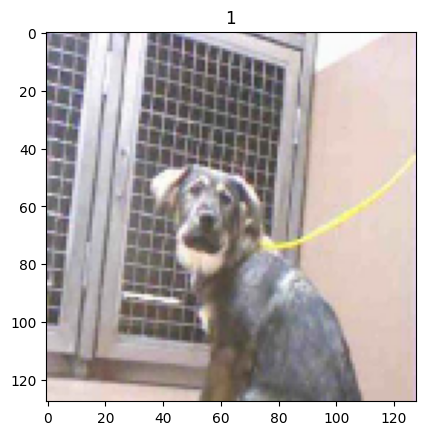

In [7]:
for image, answer in train_dataset.take(1):
    # print(image)
    # print(answer)
    plt.imshow(image[0].numpy().astype("uint8"))  # 첫 번째 이미지
    plt.title(answer[0].numpy())  # 첫 번째 이미지의 정답
    plt.show()

In [8]:
baseModel = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3), 
    include_top=False,  
    weights='imagenet'  # 이미지넷에서 학습된 가중치 사용
    )
# 기본 모델의 가중치 업데이트 중지
baseModel.trainable = False 

In [9]:
# 모델 빌드
myModel = tf.keras.models.Sequential([
    tf.keras.layers.RandomFlip('horizontal', input_shape=(128, 128, 3)),  # 좌우 반전
    tf.keras.layers.RandomRotation(0.1), # 좌우 36도 회전
    tf.keras.layers.RandomZoom(0.1), # 확대/축소
    
    tf.keras.layers.Rescaling(1./255), # 이미지 정규화(0~1)
    # tf.keras.layers.Conv2D(32, (3,3), padding='same', activation='relu'),   # 32개의 필터, 3x3 커널
    # tf.keras.layers.MaxPooling2D((2, 2)), # 풀링을 통해 데이터 크기 줄이고 특징 남기기
    # tf.keras.layers.Conv2D(64, (3,3), padding='same', activation='relu'),   # 64개의 필터
    # tf.keras.layers.MaxPooling2D((2, 2)), # 풀링 2트
    # tf.keras.layers.Dropout(0.25),   # 과적합 방지
    # tf.keras.layers.Conv2D(128, (3,3), padding='same', activation='relu'), # 128개의 필터
    # tf.keras.layers.MaxPooling2D((2, 2)), # 풀링 3트
    # tf.keras.layers.Dropout(0.5),   # 과적합 방지
    # tf.keras.layers.Flatten(),  # 2D 이미지를 1D로 변환
    # tf.keras.layers.Dense(128, activation='relu'),
    baseModel,
    tf.keras.layers.GlobalAveragePooling2D(), # 전역 평균 풀링
    tf.keras.layers.Dropout(0.5),   # 과적합 방지
    tf.keras.layers.Dense(1, activation='sigmoid') # 이진 분류이므로 1개 출력
])
# 모델 요약
myModel.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 random_flip (RandomFlip)    (None, 128, 128, 3)       0         
                                                                 
 random_rotation (RandomRot  (None, 128, 128, 3)       0         
 ation)                                                          
                                                                 
 random_zoom (RandomZoom)    (None, 128, 128, 3)       0         
                                                                 
 rescaling (Rescaling)       (None, 128, 128, 3)       0         
                                                                 
 mobilenetv2_1.00_128 (Func  (None, 4, 4, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0

In [10]:
# 모델 컴파일
myModel.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

# 모델 훈련
myHistory = myModel.fit(train_dataset,
                        validation_data=val_dataset,
                        epochs=25
                        )



Epoch 1/25


51/51 [==============================] - 13s 164ms/step - loss: 0.4950 - accuracy: 0.7616 - val_loss: 0.1687 - val_accuracy: 0.9431
Epoch 2/25
51/51 [==============================] - 7s 138ms/step - loss: 0.2874 - accuracy: 0.8734 - val_loss: 0.1299 - val_accuracy: 0.9579
Epoch 3/25
51/51 [==============================] - 7s 141ms/step - loss: 0.2337 - accuracy: 0.9024 - val_loss: 0.1201 - val_accuracy: 0.9554
Epoch 4/25
51/51 [==============================] - 7s 142ms/step - loss: 0.2219 - accuracy: 0.9067 - val_loss: 0.1148 - val_accuracy: 0.9554
Epoch 5/25
51/51 [==============================] - 7s 141ms/step - loss: 0.1851 - accuracy: 0.9265 - val_loss: 0.1064 - val_accuracy: 0.9678
Epoch 6/25
51/51 [==============================] - 7s 142ms/step - loss: 0.1901 - accuracy: 0.9191 - val_loss: 0.1087 - val_accuracy: 0.9604
Epoch 7/25
51/51 [==============================] - 7s 140ms/step - loss: 0.1978 - accuracy: 0.9191 - val_loss: 0.1025 - val_accuracy: 0.9653
Ep

Text(0.5, 0, 'Epoch')

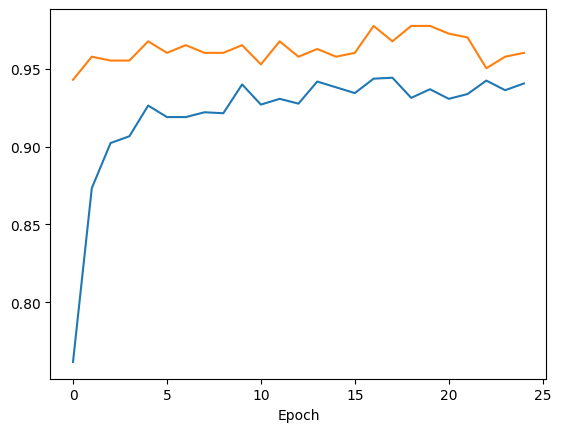

In [11]:
# 훈련 결과 검증
plt.plot(myHistory.history['accuracy'], label='accuracy')
plt.plot(myHistory.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')

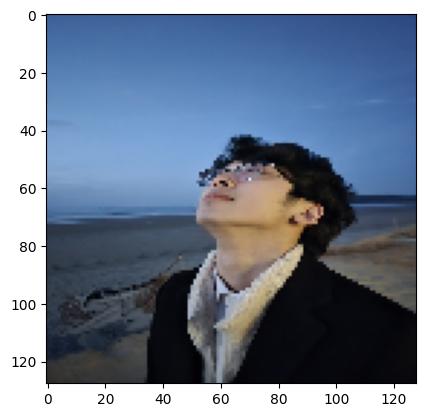

In [13]:
# 내 고양이 사진으로 판별해 보자
myImage = tf.keras.utils.load_img('./data/test_myimg.jpg', target_size=(128, 128)) #
myImage = tf.keras.utils.img_to_array(myImage)  # 이미지를 배열로 변환
myImage = myImage / 255.0 # 이미지 정규화
# 이미지 확인
plt.imshow(myImage)  
plt.show()

# 모델에 넣기 위해 차원 추가
myImage = tf.expand_dims(myImage, axis=0)

In [14]:
myPredict = myModel.predict(myImage)  
print(myPredict)
if myPredict < 0.5:
    print("냥이입니다.")
else:
    print("댕댕이입니다.")

1/1 [==============================] - 1s 1s/step
[[0.29227164]]
냥이입니다.


In [43]:
# 모델 가중치만 저장 & 불러오기
myModel.save_weights("./data/lecture07_weights.h5")
myModel.load_weights("./data/lecture07_weights.h5")
# 모델 가중치와 구조 함께 저장 & 불러오기
myModel.save("./data/lecture07_model.h5")
myModel = tf.keras.models.load_model("./data/lecture07_model.h5")

c:\Users\hyunw\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
